# Exercise 3: Neural networks in PyTorch

In this exercise you’ll implement small neural-network building blocks from scratch and use them to train a simple classifier.

You’ll cover:
- **Basic layers**: Linear, Embedding, Dropout
- **Normalization**: LayerNorm and RMSNorm
- **MLPs + residual**: composing layers into deeper networks
- **Classification**: generating a learnable dataset, implementing cross-entropy from logits, and writing a minimal training loop

As before: fill in all `TODO`s without changing function names or signatures.
Use small sanity checks and compare to PyTorch reference implementations when useful.

In [19]:
from __future__ import annotations

import torch
from torch import nn
import math

## Basic layers

In this section you’ll implement a few core layers that appear everywhere:

### `Linear`
A fully-connected layer that follows nn.Linear conventions:  
`y = x @ Wᵀ + b`

Important details:
- Parameters should be registered as `nn.Parameter`
- Store weight as (out_features, in_features) like nn.Linear.
- The forward pass should support leading batch dimensions: `x` can be shape `(..., in_features)`

### `Embedding`
An embedding table maps integer ids to vectors:
- input: token ids `idx` of shape `(...,)`
- output: vectors of shape `(..., embedding_dim)`

This is essentially a learnable lookup table.

### `Dropout`
Dropout randomly zeroes activations during training to reduce overfitting.
Implementation details:
- Only active in `model.train()` mode
- In training: drop with probability `p` and scale the kept values by `1/(1-p)` so the expected value stays the same
- In eval: return the input unchanged

## Instructions
- Do not use PyTorch reference modules for the parts you implement (e.g. don’t call nn.Linear inside your Linear).
- You may use standard tensor ops that you learned before (matmul, sum, mean, rsqrt, indexing, etc.).
- Use a parameter initialization method of your choice. We recommend something like Xavier-uniform.


In [20]:
class Linear(nn.Module):
    def __init__(self, in_features: int, out_features: int, bias: bool = True):
        super().__init__()
        self.in_features = in_features
        self.out_features = out_features
        
        # Initialize weight tensor parameter
        self.weight = nn.Parameter(torch.empty(out_features, in_features))
        if bias:
            self.bias = nn.Parameter(torch.empty(out_features))
        else:
            self.register_parameter('bias', None)
            
        self.reset_parameters()

    def reset_parameters(self):
        # Xavier uniform initialization
        bound = math.sqrt(6.0 / (self.in_features + self.out_features))
        nn.init.uniform_(self.weight, -bound, bound)
        if self.bias is not None:
            nn.init.zeros_(self.bias)

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        """
        x: (..., in_features)
        return: (..., out_features)
        """
        out = torch.einsum('...i, oi -> ...o', x, self.weight)
        if self.bias is not None:
            out = out + self.bias
        return out

In [21]:
class Embedding(nn.Module):
    def __init__(self, num_embeddings: int, embedding_dim: int):
        super().__init__()
        self.num_embeddings = num_embeddings
        self.embedding_dim = embedding_dim
        
        self.weight = nn.Parameter(torch.empty(num_embeddings, embedding_dim))
        self.reset_parameters()

    def reset_parameters(self):
        nn.init.normal_(self.weight, mean=0.0, std=1.0)

    def forward(self, idx: torch.Tensor) -> torch.Tensor:
        """
        idx: (...,) int64
        return: (..., embedding_dim)
        """
        # Index directly into weight tensor
        return self.weight[idx]

In [22]:
class Dropout(nn.Module):
    def __init__(self, p: float):
        super().__init__()
        assert 0.0 <= p < 1.0, "Dropout probability p must be in [0, 1)"
        self.p = p

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        """
        In train mode: drop with prob p and scale by 1/(1-p).
        In eval mode: return x unchanged.
        """
        if not self.training or self.p == 0.0:
            return x
        
        # Scaled dropout mask
        mask = (torch.rand_like(x) >= self.p).to(x.dtype)
        return x * mask / (1.0 - self.p)

## Normalization

Normalization layers help stabilize training by controlling activation statistics.

### LayerNorm
LayerNorm normalizes each example across its **feature dimension** (the last dimension):

- compute mean and variance over the last dimension
- normalize: `(x - mean) / sqrt(var + eps)`
- apply learnable per-feature scale and shift (`weight`, `bias`)

**In this exercise, assume `elementwise_affine=True` (always include `weight` and `bias`).**  
`weight` and `bias` each have shape `(D,)`.

LayerNorm is widely used in transformers because it does not depend on batch statistics.

### RMSNorm
RMSNorm is similar to LayerNorm but normalizes using only the root-mean-square:
- `x / sqrt(mean(x^2) + eps)` over the last dimension
- usually includes a learnable scale (`weight`)
- no mean subtraction

RMSNorm is popular in modern LLMs because it's faster.


In [23]:
class LayerNorm(nn.Module):
    def __init__(
        self, normalized_shape: int, eps: float = 1e-5, elementwise_affine: bool = True
    ):
        super().__init__()
        self.normalized_shape = normalized_shape
        self.eps = eps
        self.elementwise_affine = elementwise_affine
        
        if self.elementwise_affine:
            self.weight = nn.Parameter(torch.ones(normalized_shape))
            self.bias = nn.Parameter(torch.zeros(normalized_shape))
        else:
            self.register_parameter('weight', None)
            self.register_parameter('bias', None)

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        """
        Normalize over the last dimension.
        x: (..., D)
        """
        mean = x.mean(dim=-1, keepdim=True)
        var = x.var(dim=-1, keepdim=True, unbiased=False)
        x_norm = (x - mean) / torch.sqrt(var + self.eps)
        
        if self.elementwise_affine:
            x_norm = x_norm * self.weight + self.bias
        return x_norm

In [24]:
class RMSNorm(nn.Module):
    def __init__(self, normalized_shape: int, eps: float = 1e-8):
        super().__init__()
        self.normalized_shape = normalized_shape
        self.eps = eps
        self.weight = nn.Parameter(torch.ones(normalized_shape))

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        """
        RMSNorm: x / sqrt(mean(x^2) + eps) * weight
        over the last dimension.
        """
        rms = torch.rsqrt(x.pow(2).mean(dim=-1, keepdim=True) + self.eps)
        return x * rms * self.weight

## MLPs and residual networks

Now you’ll build larger networks by composing layers.

### MLP
An MLP is a stack of `depth` Linear layers with non-linear activations (use GELU) in between.
In this exercise you’ll support:
- configurable depth
- a hidden dimension
- optional LayerNorm between layers (a common stabilization trick)

A key skill is building networks using `nn.ModuleList` / `nn.Sequential` while keeping shapes consistent.

### Transformer-style FeedForward (FFN)
A transformer block contains a position-wise feedforward network:
- `D -> 4D -> D` (by default)
- activation is typically **GELU**

This is essentially an MLP applied independently at each token position.

### Residual wrapper
Residual connections are the simplest form of “skip connection”:
- output is `x + fn(x)`

They improve gradient flow and allow training deeper networks more reliably.

In [25]:
class MLP(nn.Module):
    def __init__(
        self,
        in_dim: int,
        hidden_dim: int,
        out_dim: int,
        depth: int,
        use_layernorm: bool = False,
    ):
        super().__init__()
        layers = []
        curr_dim = in_dim
        
        for i in range(depth):
            next_dim = hidden_dim if i < depth - 1 else out_dim
            layers.append(Linear(curr_dim, next_dim))
            
            if i < depth - 1:
                if use_layernorm:
                    layers.append(LayerNorm(next_dim))
                layers.append(nn.ReLU())
            curr_dim = next_dim
            
        self.net = nn.Sequential(*layers)

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        return self.net(x)

In [26]:
class FeedForward(nn.Module):
    """
    Transformer-style FFN: D -> 4D -> D (default)
    """

    def __init__(self, d_model: int, d_ff: int | None = None):
        super().__init__()
        d_ff = d_ff if d_ff is not None else 4 * d_model
        
        self.w1 = Linear(d_model, d_ff)
        self.act = nn.GELU()
        self.w2 = Linear(d_ff, d_model)

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        return self.w2(self.act(self.w1(x)))

In [27]:
class Residual(nn.Module):
    def __init__(self, fn: nn.Module):
        super().__init__()
        self.fn = fn

    def forward(self, x: torch.Tensor, *args, **kwargs) -> torch.Tensor:
        return x + self.fn(x, *args, **kwargs)

## Classification problem

In this section you’ll put everything together in a minimal MNIST classification experiment.

You will:
1) download and load the MNIST dataset
2) implement cross-entropy from logits (stable, using log-softmax)
3) build a simple MLP-based classifier (flatten MNIST images first)
4) write a minimal training loop
5) report train loss curve and final accuracy

The goal here is not to reach state-of-the-art accuracy, but to understand the full pipeline:
data → model → logits → loss → gradients → parameter update.

### Model notes
- We want you to combine the MLP we implemented above with the classification head we define below into one model 

### MNIST notes
- MNIST images are `28×28` grayscale.
- After `ToTensor()`, each image has shape `(1, 28, 28)` and values in `[0, 1]`.
- For an MLP classifier, we flatten to a vector of length `784`.

## Deliverables
- Include a plot of your train loss curve in the video submission as well as a final accuracy. 
- **NOTE** Here we don't grade on model performance but we expect you to achieve at least 70% accuracy to confirm a correct model implementation.

In [28]:
from torch.utils.data import DataLoader
from torchvision import datasets, transforms

In [29]:
transform = transforms.ToTensor()  # -> float32 in [0,1], shape (1, 28, 28)

train_ds = datasets.MNIST(root="data", train=True, download=True, transform=transform)
test_ds  = datasets.MNIST(root="data", train=False, download=True, transform=transform)

# DataLoaders setup
transform = transforms.ToTensor()
train_ds = datasets.MNIST(root="data", train=True, download=True, transform=transform)
test_ds = datasets.MNIST(root="data", train=False, download=True, transform=transform)

train_loader = DataLoader(train_ds, batch_size=64, shuffle=True)
test_loader = DataLoader(test_ds, batch_size=1000, shuffle=False)

In [30]:
def cross_entropy_from_logits(
    logits: torch.Tensor,
    targets: torch.Tensor,
) -> torch.Tensor:
    """
    Compute mean cross-entropy loss from logits.

    logits: (B, C)
    targets: (B,) int64

    Requirements:
    - Use log-softmax for stability (do not use torch.nn.CrossEntropyLoss, we check this in the autograder).
    """
    # log_softmax(x) = x - max(x) - log(sum(exp(x - max(x))))
    log_probs = logits - torch.logsumexp(logits, dim=-1, keepdim=True)
    
    # Gather log probabilities corresponding to target indices
    nll = -log_probs.gather(dim=-1, index=targets.unsqueeze(-1)).squeeze(-1)
    return nll.mean()

In [31]:
class ClassificationHead(nn.Module):
    def __init__(self, d_in: int, num_classes: int):
        super().__init__()
        self.proj = Linear(d_in, num_classes)

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        """
        x: (..., d_in)
        return: (..., num_classes) logits
        """
        return self.proj(x)

In [32]:
def accuracy(model: nn.Module, loader: DataLoader) -> float:
    """Evaluate model accuracy on a dataset loader."""
    model.eval()
    correct = 0
    total = 0
    
    device = next(model.parameters()).device
    with torch.no_grad():
        for x, y in loader:
            x, y = x.to(device), y.to(device)
            x_flat = x.view(x.size(0), -1)  # Flatten MNIST images (B, 1, 28, 28) -> (B, 784)
            logits = model(x_flat)
            preds = logits.argmax(dim=-1)
            correct += (preds == y).sum().item()
            total += y.size(0)
            
    return correct / total if total > 0 else 0.0

In [33]:
def train_classifier(
    model: nn.Module,
    train_data_loader: DataLoader,
    test_data_loader: DataLoader,
    lr: float,
    epochs: int,
    seed: int = 0,
) -> list[float]:
    """
    Minimal training loop for MNIST classification.

    Steps:
    - define optimizer
    - for each epoch:
        - sample minibatches
        - forward -> cross-entropy -> backward -> optimizer step
      - compute test accuracy at the end of each epoch
    - return list of training losses (one per update step)

    Requirements:
    - call model.train() during training and model.eval() during evaluation
    - do not use torch.nn.CrossEntropyLoss (use your cross_entropy_from_logits)
    """
    torch.manual_seed(seed)
    optimizer = torch.optim.Adam(model.parameters(), lr=lr)
    losses = []
    
    device = next(model.parameters()).device
    model.to(device)
    
    for epoch in range(epochs):
        model.train()
        for x, y in train_data_loader:
            x, y = x.to(device), y.to(device)
            x_flat = x.view(x.size(0), -1)
            
            optimizer.zero_grad()
            logits = model(x_flat)
            loss = cross_entropy_from_logits(logits, y)
            loss.backward()
            optimizer.step()
            
            losses.append(loss.item())
            
        test_acc = accuracy(model, test_data_loader)
        print(f"Epoch {epoch+1}/{epochs} - Test Accuracy: {test_acc * 100:.2f}%")
        
    return losses


Training on device: cuda
Epoch [1/3] | Avg Loss: 0.2702 | Test Accuracy: 95.65%
Epoch [2/3] | Avg Loss: 0.1001 | Test Accuracy: 97.00%
Epoch [3/3] | Avg Loss: 0.0696 | Test Accuracy: 97.41%


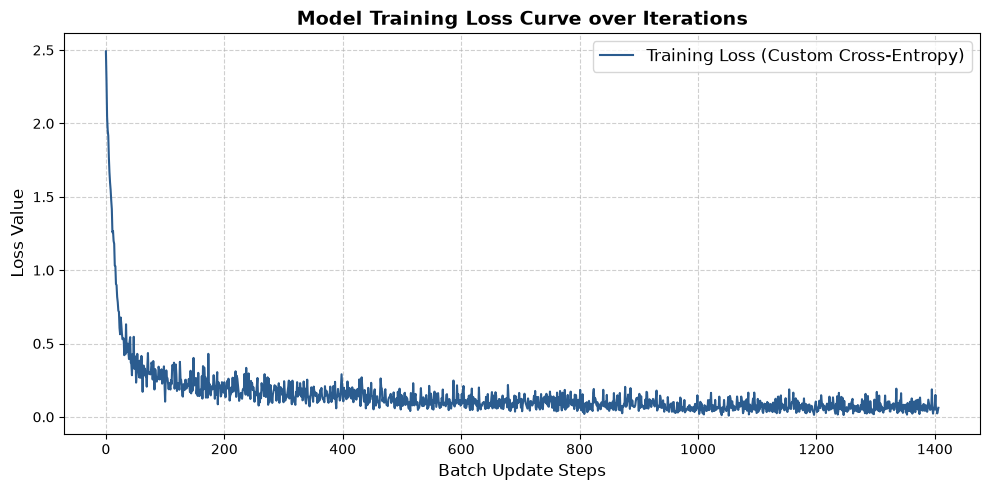

In [34]:
import torch
import torch.nn as nn
import matplotlib.pyplot as plt
from torch.utils.data import DataLoader
from torchvision import datasets, transforms

# ---------------------------------------------------------
# 1. Setup Data Pipeline
# ---------------------------------------------------------
transform = transforms.ToTensor()
train_ds = datasets.MNIST(root="data", train=True, download=True, transform=transform)
test_ds = datasets.MNIST(root="data", train=False, download=True, transform=transform)

# Using smaller batch size and subsets for a quick, responsive test run
train_loader = DataLoader(train_ds, batch_size=128, shuffle=True)
test_loader = DataLoader(test_ds, batch_size=500, shuffle=False)

# ---------------------------------------------------------
# 2. Assemble Custom Architecture
# ---------------------------------------------------------
# Here we combine your custom MLP blocks with LayerNorm and ClassificationHead
model = nn.Sequential(
    MLP(in_dim=784, hidden_dim=128, out_dim=128, depth=2, use_layernorm=True),
    nn.ReLU(),
    ClassificationHead(d_in=128, num_classes=10)
)

# ---------------------------------------------------------
# 3. Training Function with Custom Loss
# ---------------------------------------------------------
def train_and_track(model, train_loader, test_loader, lr=1e-3, epochs=3):
    optimizer = torch.optim.Adam(model.parameters(), lr=lr)
    step_losses = []
    
    device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
    model.to(device)
    
    print(f"Training on device: {device}")
    
    for epoch in range(epochs):
        model.train()
        epoch_loss = 0.0
        
        for batch_idx, (x, y) in enumerate(train_loader):
            x, y = x.to(device), y.to(device)
            # Flatten image: (B, 1, 28, 28) -> (B, 784)
            x_flat = x.view(x.size(0), -1)
            
            optimizer.zero_grad()
            logits = model(x_flat)
            
            # Uses your custom stable cross-entropy function!
            loss = cross_entropy_from_logits(logits, y)
            loss.backward()
            optimizer.step()
            
            step_losses.append(loss.item())
            epoch_loss += loss.item()
            
        # Evaluate accuracy at the end of each epoch
        acc = accuracy(model, test_loader)
        print(f"Epoch [{epoch+1}/{epochs}] | Avg Loss: {epoch_loss/len(train_loader):.4f} | Test Accuracy: {acc*100:.2f}%")
        
    return step_losses

# Run the training process
losses = train_and_track(model, train_loader, test_loader, lr=1e-3, epochs=3)

# ---------------------------------------------------------
# 4. Plot Training Loss Curve
# ---------------------------------------------------------
plt.figure(figsize=(10, 5))
plt.plot(losses, label="Training Loss (Custom Cross-Entropy)", color="#2b5c8f", linewidth=1.5)
plt.title("Model Training Loss Curve over Iterations", fontsize=14, fontweight='bold')
plt.xlabel("Batch Update Steps", fontsize=12)
plt.ylabel("Loss Value", fontsize=12)
plt.grid(True, linestyle="--", alpha=0.6)
plt.legend(fontsize=12)
plt.tight_layout()
plt.show()

# Comprehensive Architecture & Data-Flow Breakdown

## 1. End-to-End Data Flow: The Journey of a Tensor
* **Input Stage:** Raw data samples (e.g., MNIST images of shape `(B, 1, 28, 28)`) are loaded via `DataLoader`.
* **Preprocessing & Flattening:** Images are flattened into 1D feature vectors of shape `(B, 784)` to match standard feed-forward input requirements.
* **Custom Linear Projections:** 
  - Instead of relying on black-box PyTorch modules, the custom `Linear` layer uses Einstein summation (`torch.einsum('...i, oi -> ...o')`) to perform matrix multiplication across arbitrary leading batch dimensions.
  - Weights are initialized using Xavier uniform bounds to stabilize variance at initialization.
* **Normalization & Activations:** 
  - `LayerNorm` computes the mean and variance across the final feature dimension, normalizing values to prevent internal covariate shift, followed by learned affine scaling (`weight` and `bias`).
* **Loss Calculation (Stable Cross-Entropy):** 
  - Raw logits are converted to log-probabilities using `logsumexp` subtraction to prevent floating-point underflow/overflow.
  - The negative log-likelihood loss is extracted efficiently via `.gather()`.
* **Optimization Loop:** 
  - Gradients are accumulated via `loss.backward()` and consumed by the optimizer to update model parameters in-place.

---

## 2. Core Code Components & Their Roles
* **`Linear(nn.Module)`**: Implements explicit matrix multiplication via `einsum` and manages parameter weight tensors and optional biases.
* **`LayerNorm(nn.Module)`**: Normalizes activations element-wise over the last dimension using mean, variance, and a small epsilon ($\epsilon$) for numerical stability.
* **`MLP(nn.Module)`**: Stacks linear layers, normalization blocks, and non-linear activations (`ReLU`) sequentially based on a configurable depth.
* **`cross_entropy_from_logits`**: Manually computes stable classification loss without utilizing built-in high-level wrappers.